# Plot CCA

## Parametri

In [5]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.multitest import multipletests

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from source.cca import load_tensor

arrangement_types = ["bass", "full", "full_no_bass", "harm", "lead"]

train_results_path = project_root / "data" / "results" / "cca" / "permutation_test.parquet"
test_results_path = project_root / "data" / "results" / "cca" / "permutation_test_conferma.parquet"
tensors_dir = project_root / "data" / "results" / "tensors"
models_dir = project_root / "data" / "model"

# batteria vera contro le altre: p con posizioni casuali
seed = 6
n_draws_test = 100_000

## Caricamento dei risultati

In [6]:
train_read = pd.read_parquet(train_results_path)
train_results = train_read.set_index("classe").loc[arrangement_types]

test_read = pd.read_parquet(test_results_path)
test_results = test_read.set_index("classe").loc[arrangement_types]

results = pd.DataFrame({
    "train_corr": train_results["observation"],
    "train_null_mean": train_results["null_media"],
    "train_p_holm": train_results["p_holm"],
    "test_corr": test_results["observation"],
    "test_null_mean": test_results["null_media"],
    "test_p_holm": test_results["p_holm"],
    "n_train": train_results["n"],
    "n_test": test_results["n_test"],
})

## Prestazioni CCA

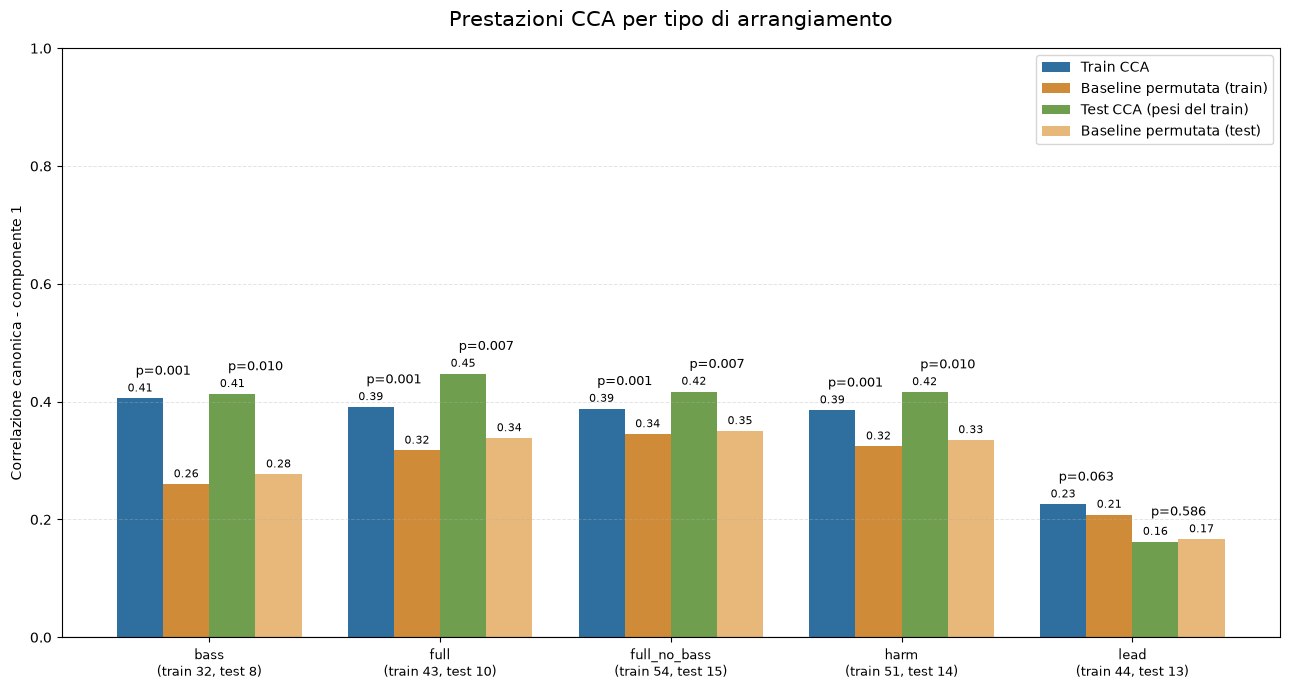

In [7]:
output_plot = project_root / "data" / "results" / "plots" / "cca_performance.pdf"

labels = []
for arrangement_type in arrangement_types:
    n_train = results.loc[arrangement_type, "n_train"]
    n_test = results.loc[arrangement_type, "n_test"]
    labels.append(f"{arrangement_type}\n(train {n_train}, test {n_test})")
x = np.arange(len(results))
width = 0.2

fig, ax = plt.subplots(figsize=(13, 7))

train_bars = ax.bar(x - 1.5 * width, results["train_corr"], width, label="Train CCA", color="#2f6f9f")
train_null_bars = ax.bar(x - 0.5 * width, results["train_null_mean"], width, label="Baseline permutata (train)", color="#d08b39")
test_bars = ax.bar(x + 0.5 * width, results["test_corr"], width, label="Test CCA (pesi del train)", color="#6f9e4f")
test_null_bars = ax.bar(x + 1.5 * width, results["test_null_mean"], width, label="Baseline permutata (test)", color="#e8b77a")

ax.axhline(0, color="#333333", linewidth=0.8)
ax.set_title("Prestazioni CCA per tipo di arrangiamento", fontsize=15, pad=16)
ax.set_ylabel("Correlazione canonica - componente 1")
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)

y_values = results[["train_corr", "train_null_mean", "test_corr", "test_null_mean"]].to_numpy(dtype=float)
ax.set_ylim(min(0, y_values.min() - 0.12), max(1.0, y_values.max() + 0.12))
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.35)
ax.legend(loc="upper right")

# p-value corretto con Holm sopra ogni coppia (osservato, baseline)
for idx, c in enumerate(arrangement_types):
    for split, centro in [("train", idx - width), ("test", idx + width)]:
        p = results.loc[c, f"{split}_p_holm"]
        ymax = max(results.loc[c, f"{split}_corr"], results.loc[c, f"{split}_null_mean"])
        ax.text(
            centro, ymax + 0.035, f"p={p:.3f}",
            ha="center", va="bottom", fontsize=9,
        )

ax.bar_label(train_bars, fmt="%.2f", padding=3, fontsize=8)
ax.bar_label(train_null_bars, fmt="%.2f", padding=3, fontsize=8)
ax.bar_label(test_bars, fmt="%.2f", padding=3, fontsize=8)
ax.bar_label(test_null_bars, fmt="%.2f", padding=3, fontsize=8)

fig.tight_layout()

output_plot.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_plot, dpi=180, bbox_inches="tight")
plt.show()

## Batteria vera del test contro le altre del train


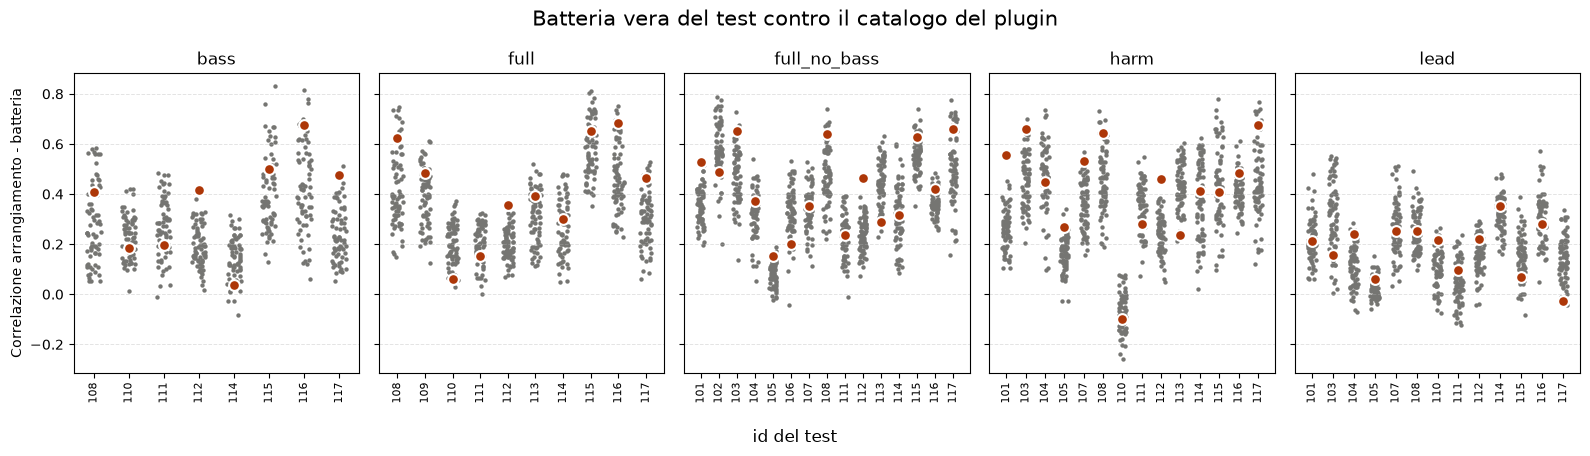

In [8]:
output_drum = project_root / "data" / "results" / "plots" / "cca_batteria_vera_contro_altre.pdf"

from plugin.groove_matcher import matching

drums = np.load(tensors_dir / "tensor_drums.npz") # catalogo del plugin

fig, axes = plt.subplots(1, 5, figsize=(16, 4.5), sharey=True)
positions = []
for i, arrangement_type in enumerate(arrangement_types):
    ax = axes[i]  # un grafico per ogni tipo di arrangiamento
    test = load_tensor(tensors_dir / f"tensor_test_{arrangement_type}.npz")

    for k in range(len(test["X"])):
        # scores[0] = batteria vera, scores[1:] = le altre batterie del catalogo
        candidates = np.concatenate([test["Y"][k:k+1], drums["Y"]])
        scores = matching(arrangement_type, test["X"][k], candidates)
        true, others = scores[0], scores[1:]

        rng = np.random.default_rng(k).uniform(-0.2, 0.2, len(others)) # allarga i punti grigi per non sovrapporli
        ax.scatter(np.full(len(others), k + rng), others, s=10, color="#757572", linewidth=0)
        ax.scatter(k, true, s=60, color="#ad3708", edgecolor="white", linewidth=1.5, zorder=3)
        positions.append(dict(classe=arrangement_type, id=int(test["ids"][k]), posizione=int(np.sum(others > true)) + 1))

    ax.set_xticks(range(len(test["X"])))
    ax.set_xticklabels(test["ids"], rotation=90, fontsize=8)
    ax.set_title(arrangement_type)
    ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.35)

axes[0].set_ylabel("Correlazione arrangiamento - batteria")
fig.suptitle("Batteria vera del test contro il catalogo del plugin", fontsize=15)
fig.supxlabel("id del test")
fig.tight_layout()
fig.savefig(output_drum, dpi=180, bbox_inches="tight")
plt.show()

In [9]:
positions = pd.DataFrame(positions)
n_candidates = len(drums["Y"]) + 1  # libreria + batteria vera
rows = []
for arrangement_type in arrangement_types:
    group = positions[positions["classe"] == arrangement_type]
    n_test = len(group)
    rank = ((group["posizione"] - 1) / (n_candidates - 1)).mean()
    rows.append(dict(
        classe=arrangement_type,
        tracce=n_test,
        candidati=n_candidates,
        migliore=1 - rank,
        top1=int(np.sum(group["posizione"] == 1)),
        top3=int(np.sum(group["posizione"] <= 3)),
        top5=int(np.sum(group["posizione"] <= 5)),
        top5_media=np.mean(group["posizione"] <= 5),
    ))

summary = pd.DataFrame(rows).set_index("classe")
print(summary)

              tracce  candidati  migliore  top1  top3  top5  top5_media
classe                                                                 
bass               8         71  0.648214     1     2     2    0.250000
full              10         71  0.677143     1     1     2    0.200000
full_no_bass      15         71  0.652381     2     3     3    0.200000
harm              14         71  0.689796     1     4     5    0.357143
lead              13         71  0.531868     0     0     0    0.000000


## Stile delle matrici

In [10]:
from matplotlib.colors import LinearSegmentedColormap

fig_width = 6.3  # pollici

ink = "#0b0b0b"            # testo principale
ink_secondary = "#52514e"  # etichette
empty_cell = "#f0efec"     # step vuoti nella matrice di batteria

# scala sequenziale a una sola tinta, dal bianco (zero) al blu scuro (massimo)
sequential = LinearSegmentedColormap.from_list(
    "sequenziale_blu", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

matrix_style = {
    "font.size": 9,
    "axes.labelsize": 8.5,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "text.color": ink,
    "axes.labelcolor": ink_secondary,
    "xtick.labelcolor": ink_secondary,
    "ytick.labelcolor": ink_secondary,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,  # testo del PDF selezionabile e modificabile
}


def matrix_figure():
    """figura per le matrici con margini fissi: batteria e arrangiamento restano allineate una sopra l'altra"""
    fig = plt.figure(figsize=(fig_width, 1.6))
    ax = fig.add_axes((0.2, 0.27, 0.68, 0.69))
    cax = fig.add_axes((0.895, 0.27, 0.012, 0.69))
    return fig, ax, cax


def draw_step_matrix(ax, M, labels, cmap, vmin, cell_gaps):
    """matrice canali x 128 step; righe e battute separate da spazi bianchi"""
    n_rows, n_steps = M.shape
    if cell_gaps:  # batteria: ogni sedicesimo è una cella separata
        image = ax.pcolormesh(M, cmap=cmap, vmin=vmin, vmax=1, edgecolors="white", linewidth=0.4)
        for s in range(4, n_steps, 4):  # movimenti
            ax.axvline(s, color="white", linewidth=1.0)
    else:  # arrangiamento: valori continui
        image = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=1, aspect="auto", interpolation="nearest",
                          extent=(0, n_steps, n_rows, 0))
    for s in range(16, n_steps, 16):  # battute
        ax.axvline(s, color="white", linewidth=2.5)
    for r in range(1, n_rows):
        ax.axhline(r, color="white", linewidth=2.5)

    ax.set_xlim(0, n_steps)
    ax.set_ylim(n_rows, 0)
    ax.set_yticks(np.arange(n_rows) + 0.5, labels)
    ax.set_xticks(np.arange(8) * 16 + 8, [str(b + 1) for b in range(8)])
    ax.set_xlabel("Battuta (16 sedicesimi ciascuna)")
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return image


def add_colorbar(fig, image, cax, label):
    colorbar = fig.colorbar(image, cax=cax, ticks=[0, 0.5, 1])
    colorbar.outline.set_visible(False)
    colorbar.ax.tick_params(length=0, labelsize=7)
    colorbar.set_label(label, fontsize=7.5, color=ink_secondary)
    return colorbar

## Esempio di matrice di batteria

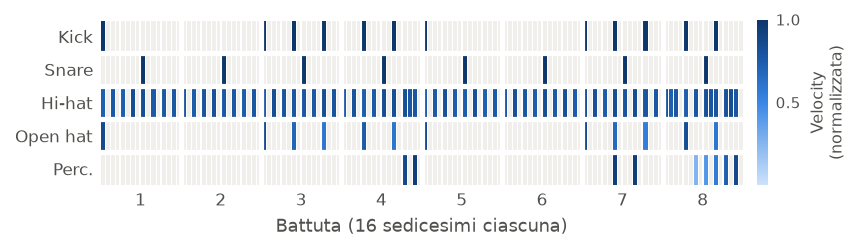

In [11]:
output_drum_matrix = project_root / "data" / "results" / "plots" / "matrice_batteria.pdf"

drum_id = 15  # midi_15_162.mid
drum_channels = ["Kick", "Snare", "Hi-hat", "Open hat", "Perc."]  # stesso ordine dei canali in extract_vectors

drums = np.load(tensors_dir / "tensor_drums.npz")
D = drums["Y"][list(drums["ids"]).index(drum_id)]  # (5, 128), velocity normalizzata tra 0 e 1

# step senza colpi in grigio chiarissimo, colpi in blu tanto più scuro quanto più forte è la velocity
drum_cmap = LinearSegmentedColormap.from_list("velocity", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
drum_cmap.set_under(empty_cell)

with plt.rc_context(matrix_style):
    fig, ax, cax = matrix_figure()
    image = draw_step_matrix(ax, D, drum_channels, drum_cmap, vmin=1e-6, cell_gaps=True)
    add_colorbar(fig, image, cax, "Velocity\n(normalizzata)")
    fig.savefig(output_drum_matrix)
plt.show()

## Esempio di matrice di arrangiamento

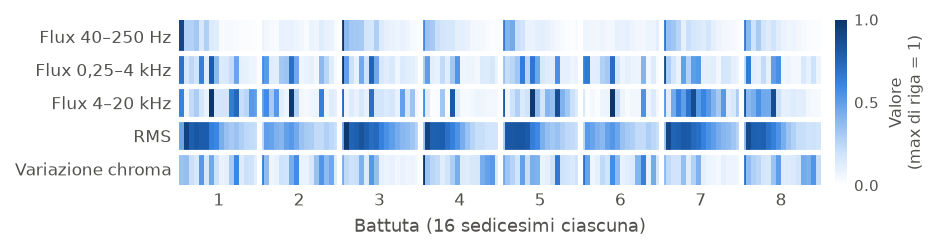

In [12]:
output_arrangement_matrix = project_root / "data" / "results" / "plots" / "matrice_arrangiamento.pdf"

arrangement_id = 15  # sample_melodic_15_162.wav, stessa coppia della batteria sopra
example_type = "full"  # tipo di arrangiamento mostrato

arrangements = np.load(tensors_dir / f"tensor_train_{example_type}.npz")
A = arrangements["X"][list(arrangements["ids"]).index(arrangement_id)]  # (5, 128), valori grezzi
arrangement_channels = ["Flux 40–250 Hz", "Flux 0,25–4 kHz", "Flux 4–20 kHz", "RMS", "Variazione chroma"]

# le righe hanno scale diverse: ognuna divisa per il proprio massimo, solo per la figura
A_plot = A / A.max(axis=1, keepdims=True)

with plt.rc_context(matrix_style):
    fig, ax, cax = matrix_figure()
    image = draw_step_matrix(ax, A_plot, arrangement_channels, sequential, vmin=0, cell_gaps=False)
    add_colorbar(fig, image, cax, "Valore\n(max di riga = 1)")
    fig.savefig(output_arrangement_matrix)
plt.show()